In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
import os
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import minimum_spanning_tree


In [2]:
# Load and scale the dataset
data_path = "../data/clustering_dataset.csv"
df = pd.read_csv(data_path)

scaler = StandardScaler()
X = scaler.fit_transform(df.values)

print(f"Data Loaded and Scaled. Shape: {X.shape}")

Data Loaded and Scaled. Shape: (12000, 2)


In [3]:
class HDBSCAN:
    def __init__(self, min_cluster_size=120, min_samples=25):
        self.min_cluster_size = min_cluster_size
        self.min_samples = min_samples
        self.labels_ = None
        self.mst_ = None
        self.core_dists_ = None

    def fit(self, X):
        n = X.shape[0]

        # ============================================================
        # 1. CORE DISTANCES (Density Estimation)
        # ============================================================
        nbrs = NearestNeighbors(n_neighbors=self.min_samples).fit(X)
        distances, indices = nbrs.kneighbors(X)
        self.core_dists_ = distances[:, -1]

        # ============================================================
        # 2. MUTUAL REACHABILITY GRAPH
        # ============================================================
        rows, cols, data = [], [], []

        for i in range(n):
            for j_idx, d in zip(indices[i], distances[i]):
                if i == j_idx:
                    continue

                # Mutual Reachability Distance
                mreach = max(self.core_dists_[i],
                             self.core_dists_[j_idx],
                             d)

                rows.append(i)
                cols.append(j_idx)
                data.append(mreach)

        graph = coo_matrix((data, (rows, cols)), shape=(n, n))

        # ============================================================
        # 3. MINIMUM SPANNING TREE
        # ============================================================
        self.mst_ = minimum_spanning_tree(graph)

        mst_rows, mst_cols = self.mst_.nonzero()
        mst_data = self.mst_.data

        # Sort edges from smallest to largest (hierarchical build)
        edges = sorted(zip(mst_data, mst_rows, mst_cols),
                       key=lambda x: x[0])

        # ============================================================
        # 4. BUILD FULL HIERARCHY (NO PERCENTILE CUT)
        # ============================================================

        parent = np.arange(2 * n)
        size = np.ones(2 * n)

        def find(i):
            while parent[i] != i:
                parent[i] = parent[parent[i]]
                i = parent[i]
            return i

        next_cluster_id = n

        # Build hierarchy by merging smallest edges first
        for w, u, v in edges:
            root_u = find(u)
            root_v = find(v)

            if root_u != root_v:
                parent[root_u] = next_cluster_id
                parent[root_v] = next_cluster_id
                size[next_cluster_id] = size[root_u] + size[root_v]
                parent[next_cluster_id] = next_cluster_id
                next_cluster_id += 1

        # ============================================================
        # 5. AUTOMATIC CLUSTER EXTRACTION
        #    (based only on min_cluster_size)
        # ============================================================

        final_labels = np.full(n, -1)
        cluster_map = {}
        current_label = 0

        for i in range(n):
            root = find(i)

            # Keep only clusters that satisfy minimum size
            if size[root] >= self.min_cluster_size:
                if root not in cluster_map:
                    cluster_map[root] = current_label
                    current_label += 1

                final_labels[i] = cluster_map[root]

        self.labels_ = final_labels

        return self

In [4]:
MIN_CLUSTER_SIZE = 50 
MIN_SAMPLES = 25

start_time = time.time()
model = HDBSCAN(min_cluster_size=MIN_CLUSTER_SIZE, min_samples=MIN_SAMPLES)
model.fit(X)
run_time = time.time() - start_time

labels = model.labels_
n_clusters = len(np.unique(labels[labels != -1]))
n_noise = np.sum(labels == -1)

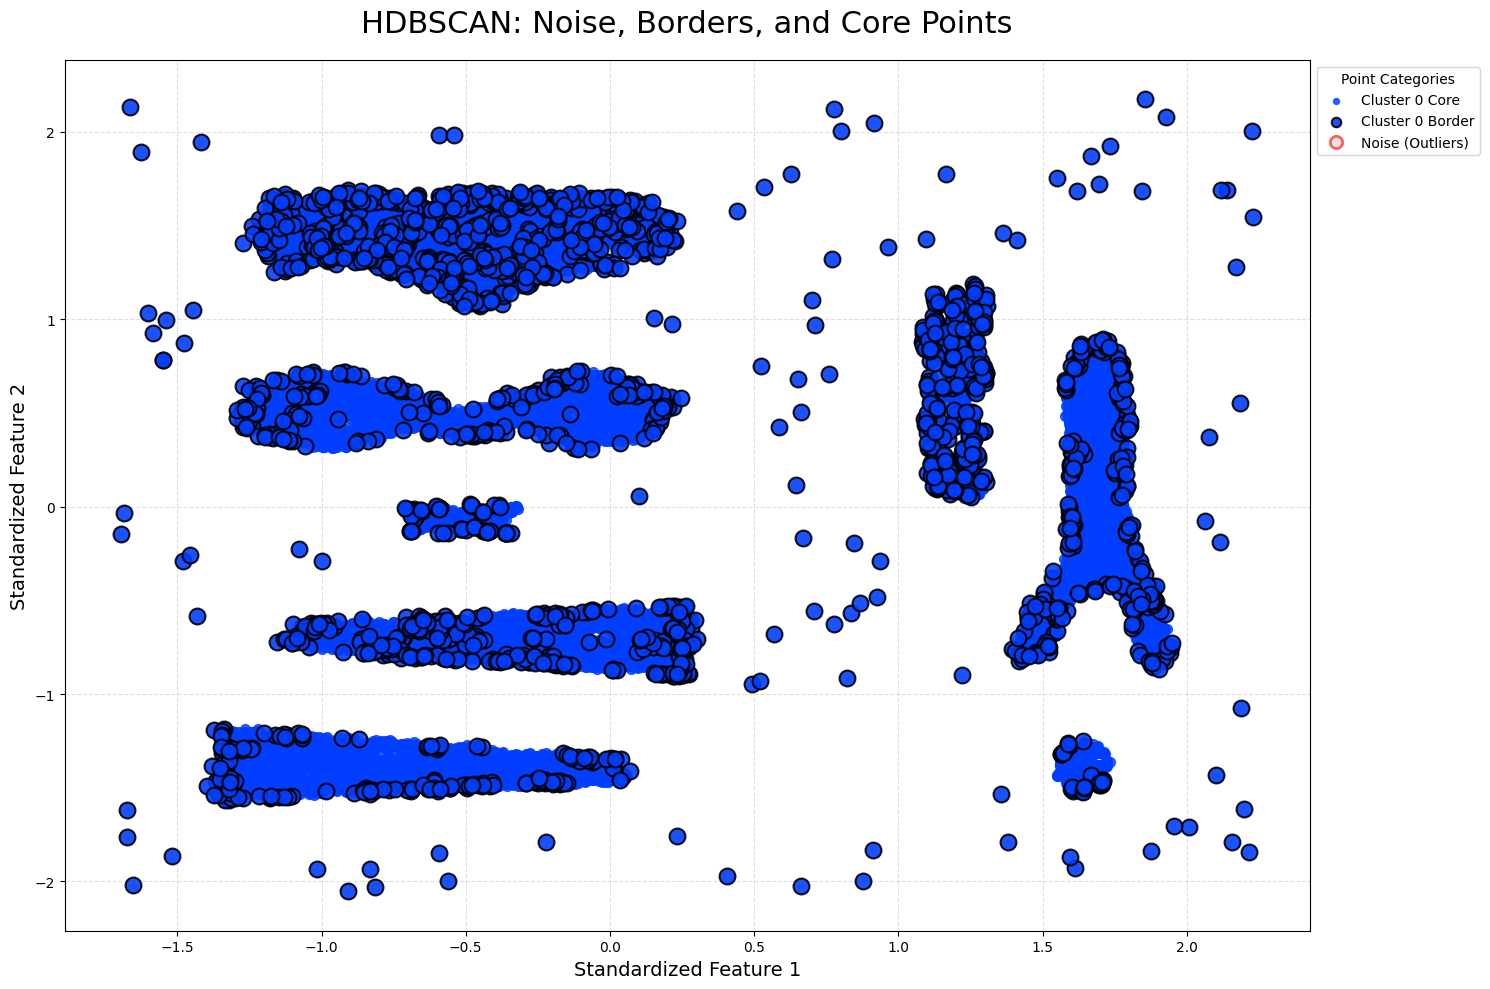

In [5]:
# 1. Prepare Categorization
unique_clusters = np.unique(labels[labels != -1])
is_noise = (labels == -1)
is_border = np.zeros(X.shape[0], dtype=bool)
is_core = np.zeros(X.shape[0], dtype=bool)

# For each cluster, define the 20% most 'sparse' points as Borders
for cluster_id in unique_clusters:
    idx = np.where(labels == cluster_id)[0]
    cluster_core_dists = model.core_dists_[idx]
    threshold = np.percentile(cluster_core_dists, 80)
    is_border[idx[cluster_core_dists >= threshold]] = True
    is_core[idx[cluster_core_dists < threshold]] = True

# 2. Plotting
plt.figure(figsize=(15, 10))
palette = sns.color_palette("bright", len(unique_clusters))

# Plot Core Points (Normal size)
for i, l in enumerate(unique_clusters):
    mask = (labels == l) & is_core
    plt.scatter(X[mask, 0], X[mask, 1], color=palette[i], s=50, 
                label=f'Cluster {l} Core', alpha=0.8, zorder=2)

# Plot Border Points (Large, Cluster Color, Black Edge)
for i, l in enumerate(unique_clusters):
    mask = (labels == l) & is_border
    plt.scatter(X[mask, 0], X[mask, 1], color=palette[i], s=130, 
                edgecolors='black', linewidth=1.5, label=f'Cluster {l} Border', alpha=0.9, zorder=3)

# Plot Noise (Very Large, Grey Fill, Red Edge)
plt.scatter(X[is_noise, 0], X[is_noise, 1], color='lightgrey', s=220, 
            edgecolors='red', linewidth=2.0, label='Noise (Outliers)', alpha=0.6, zorder=1)

# 3. Final Styling
plt.title("HDBSCAN: Noise, Borders, and Core Points", fontsize=22, pad=20)
plt.legend(markerscale=0.6, loc='upper left', bbox_to_anchor=(1, 1), title="Point Categories")
plt.xlabel("Standardized Feature 1", fontsize=14)
plt.ylabel("Standardized Feature 2", fontsize=14)
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

In [6]:


# Metric calculation - Masking noise points to evaluate cluster quality
mask = labels != -1
if n_clusters > 1:
    sil = silhouette_score(X[mask], labels[mask])
    db = davies_bouldin_score(X[mask], labels[mask])
    ch = calinski_harabasz_score(X[mask], labels[mask])
else:
    sil = db = ch = np.nan

# Logging to results.csv
results_path = "../results.csv"
res_df = pd.DataFrame([{
    "model": "hdbscan", 
    "n_clusters": n_clusters, 
    "epsilon": "N/A", 
    "min_pts": MIN_SAMPLES,
    "inertia": 0, 
    "silhouette": sil, 
    "davies_bouldin_score": db, 
    "calinski_harabasz_score": ch, 
    "n_noise": n_noise, 
    "run_time": run_time
}])
res_df.to_csv(results_path, mode='a', header=not os.path.exists(results_path), index=False)

print(f"--- HDBSCAN COMPLETE ---")
print(f"Clusters: {n_clusters} | Noise: {n_noise} | Time: {run_time:.2f}s")
print(f"Silhouette (Filtered): {sil:.4f}")

--- HDBSCAN COMPLETE ---
Clusters: 1 | Noise: 0 | Time: 2.37s
Silhouette (Filtered): nan
